# **MiniMax-H3-Image (T2I R2I)**
- Github repo: https://github.com/MiniMax-AI/MiniMax-H3-Image

- Notebook source: https://github.com/Isi-dev/Google-Colab_Notebooks

In [ ]:
# @title 💥 1. Prepare Environment & Download Models {"single-column":true}
import os
import sys
import shutil
import subprocess
import re
import time
import gc
from pathlib import Path
from IPython.display import clear_output, display, HTML, Image as IPImage

os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

# 1. Directory alignment & Repositories Setup
%cd /content
if not os.path.exists("ComfyUI"):
    !git clone https://github.com/comfyanonymous/ComfyUI.git

%cd /content/ComfyUI/custom_nodes
if not os.path.exists("ComfyUI_GGUF"):
    !git clone --branch leejet_27_09_2026 https://github.com/Isi-dev/ComfyUI_GGUF.git

# Ensure ComfyUI_GGUF loader recognizes the "minimax_h3" architecture
gguf_loader_path = "/content/ComfyUI/custom_nodes/ComfyUI_GGUF/loader.py"
if os.path.exists(gguf_loader_path):
    with open(gguf_loader_path, "r") as f:
        loader_code = f.read()
    if '"minimax_h3"' not in loader_code and "'minimax_h3'" not in loader_code:
        loader_code = loader_code.replace('"qwen_image"', '"qwen_image", "minimax_h3"')
        with open(gguf_loader_path, "w") as f:
            f.write(loader_code)

%cd /content/ComfyUI
!pip install -r requirements.txt
!pip install gguf huggingface_hub hf_transfer sageattention triton imageio imageio-ffmpeg opencv-python
!apt -y install -qq aria2 ffmpeg

clear_output()
print("✅ Repositories & core requirements installed.")

# @markdown ---
# @markdown ### **Authentication & Tokens**
hf_token = "" # @param {type:"string"}
civitai_token = "" # @param {type:"string"}

# @markdown ---
# @markdown ### **Core Model Presets & Custom URLs**
# @markdown Select a preset or paste any direct HuggingFace / Civitai URL below (supports `.safetensors` and `.gguf`):
diffusion_preset = "Comfy-Org INT8 ConvRot (21 GB - Balanced)" # @param ["Comfy-Org INT8 ConvRot (21 GB - Balanced)", "Comfy-Org W4A8 (12.5 GB - Low VRAM)", "Comfy-Org BF16 (Highest Quality)", "GGUF Q4_K_M (Low VRAM GGUF)", "Use Custom Diffusion URL Below"]
custom_diffusion_url = "" # @param {type:"string"}

text_encoder_preset = "Comfy-Org Qwen3-VL 32B NVFP4 AWQ (15.7 GB)" # @param ["Comfy-Org Qwen3-VL 32B NVFP4 AWQ (15.7 GB)", "Comfy-Org Qwen3-VL 32B INT8 ConvRot", "Unsloth Qwen3-VL 32B GGUF Q4_K_M (18.2 GB)", "Use Custom Text Encoder URL Below"]
custom_text_encoder_url = "" # @param {type:"string"}

vae_model_url = "https://huggingface.co/Comfy-Org/MiniMax-H3-Image/resolve/main/vae/minimax_h3_image_vae_fp16.safetensors" # @param {type:"string"}

# @markdown ---
# @markdown ### **Optional Custom LoRAs (HuggingFace or Civitai URLs)**
download_lora_1 = False # @param {type:"boolean"}
lora_1_url = "" # @param {type:"string"}

download_lora_2 = False # @param {type:"boolean"}
lora_2_url = "" # @param {type:"string"}

download_lora_3 = False # @param {type:"boolean"}
lora_3_url = "" # @param {type:"string"}

download_lora_4 = False # @param {type:"boolean"}
lora_4_url = "" # @param {type:"string"}

download_lora_5 = False # @param {type:"boolean"}
lora_5_url = "" # @param {type:"string"}

# Resolve Diffusion URL
if diffusion_preset == "Use Custom Diffusion URL Below" and custom_diffusion_url.strip():
    resolved_diffusion_url = custom_diffusion_url.strip()
elif "W4A8" in diffusion_preset:
    resolved_diffusion_url = "https://huggingface.co/Comfy-Org/MiniMax-H3-Image/resolve/main/diffusion_models/minimax_h3_image_pruned_w4a8.safetensors"
elif "BF16" in diffusion_preset:
    resolved_diffusion_url = "https://huggingface.co/Comfy-Org/MiniMax-H3-Image/resolve/main/diffusion_models/minimax_h3_image_pruned_bf16.safetensors"
elif "GGUF" in diffusion_preset:
    resolved_diffusion_url = custom_diffusion_url.strip() if custom_diffusion_url.strip() else "https://huggingface.co/unsloth/MiniMax-H3-Image-GGUF/resolve/main/minimax-h3-image-Q4_K_M.gguf"
else:
    resolved_diffusion_url = custom_diffusion_url.strip() if custom_diffusion_url.strip() else "https://huggingface.co/Comfy-Org/MiniMax-H3-Image/resolve/main/diffusion_models/minimax_h3_image_pruned_int8_convrot.safetensors"

# Resolve Text Encoder URL
if text_encoder_preset == "Use Custom Text Encoder URL Below" and custom_text_encoder_url.strip():
    resolved_clip_url = custom_text_encoder_url.strip()
elif "INT8" in text_encoder_preset:
    resolved_clip_url = "https://huggingface.co/Comfy-Org/MiniMax-H3-Image/resolve/main/text_encoders/qwen3vl_32b_minimax_h3_int8_convrot.safetensors"
elif "GGUF" in text_encoder_preset:
    resolved_clip_url = "https://huggingface.co/unsloth/MiniMax-H3-GGUF/resolve/main/qwen3vl_32b_minimax_h3-Q4_K_M.gguf"
else:
    resolved_clip_url = custom_text_encoder_url.strip() if custom_text_encoder_url.strip() else "https://huggingface.co/Comfy-Org/MiniMax-H3-Image/resolve/main/text_encoders/qwen3vl_32b_minimax_h3_nvfp4_awq.safetensors"

os.environ["HF_HUB_ENABLE_HF_TRANSFER"] = "1"
from huggingface_hub import hf_hub_download

def download_hf_file(repo_id, repo_relative_path, local_destination, token=None):
    if not repo_relative_path or repo_relative_path == "None":
        return None
    os.makedirs(local_destination, exist_ok=True)
    filename = os.path.basename(repo_relative_path)
    destination = os.path.join(local_destination, filename)
    if os.path.isfile(destination):
        print(f"⏭️ Already exists: {destination}")
        return filename
    print(f"⬇️ Downloading HF File: {repo_id}/{repo_relative_path}")
    try:
        downloaded_path = hf_hub_download(
            repo_id=repo_id,
            filename=repo_relative_path,
            token=token if token else None
        )
        shutil.copy2(downloaded_path, destination)
        try:
            os.remove(downloaded_path)
        except Exception:
            pass
        print(f"✅ Downloaded: {destination}")
        return filename
    except Exception as e:
        print(f"❌ Download failed for {repo_relative_path}: {e}")
        return None

def download_civitai_model(civitai_link, token, folder="models/loras"):
    os.makedirs(folder, exist_ok=True)
    try:
        model_id = civitai_link.split("/models/")[1].split("?")[0]
    except IndexError:
        raise ValueError("Invalid Civitai URL format. Expected: https://civitai.com/api/download/models/<ID>")
    civitai_url = f"https://civitai.com/api/download/models/{model_id}?type=Model&format=SafeTensor"
    if token:
        civitai_url += f"&token={token}"
    timestamp = time.strftime("%Y%m%d_%H%M%S")
    filename = f"civitai_model_{timestamp}.safetensors"
    full_path = os.path.join(folder, filename)
    print(f"⬇️ Downloading Civitai model to {full_path}...")
    cmd = f'wget --max-redirect=10 --show-progress "{civitai_url}" -O "{full_path}"'
    os.system(cmd)
    if os.path.exists(full_path) and os.path.getsize(full_path) > 0:
        print(f"✅ Civitai Download Complete: {filename}")
        return filename
    else:
        print("❌ Civitai Download failed.")
        return None

def download_generic_url(url, dest_dir, token_hf="", token_civitai=""):
    if not url or not url.strip():
        return None
    url = url.strip()
    if "civitai.com" in url.lower():
        return download_civitai_model(url, token_civitai, dest_dir)
    hf_match = re.search(r'huggingface\.co/([^/]+/[^/]+)/(?:resolve|blob)/[^/]+/(.+)', url)
    if hf_match:
        repo_id = hf_match.group(1)
        rel_path = hf_match.group(2)
        return download_hf_file(repo_id, rel_path, dest_dir, token_hf)
    filename = url.split('/')[-1].split('?')[0]
    os.makedirs(dest_dir, exist_ok=True)
    cmd = ['aria2c', '--console-log-level=error', '-c', '-x', '16', '-s', '16', '-k', '1M', '-d', dest_dir, '-o', filename, url]
    subprocess.run(cmd, check=False)
    return filename

token_str = hf_token.strip()
civ_token_str = civitai_token.strip()

print("--- Downloading Base Models ---")
unet_model_file = download_generic_url(resolved_diffusion_url, "models/diffusion_models", token_str, civ_token_str)
text_encoder_file = download_generic_url(resolved_clip_url, "models/text_encoders", token_str, civ_token_str)
image_vae_file = download_generic_url(vae_model_url, "models/vae", token_str, civ_token_str)

lora_files = []
lora_configs = [
    (download_lora_1, lora_1_url),
    (download_lora_2, lora_2_url),
    (download_lora_3, lora_3_url),
    (download_lora_4, lora_4_url),
    (download_lora_5, lora_5_url),
]

print("--- Downloading Custom LoRAs ---")
for idx, (enabled, url) in enumerate(lora_configs, 1):
    if enabled and url.strip():
        fname = download_generic_url(url, "models/loras", token_str, civ_token_str)
        lora_files.append(fname)
        if fname:
            print(f"LoRA {idx} registered: {fname}")
    else:
        lora_files.append(None)

# Initialize ComfyUI Classes & Execution Imports
import torch
import numpy as np
from PIL import Image

sys.path.insert(0, '/content/ComfyUI')
from comfy import model_management
from nodes import (
    UNETLoader,
    CLIPLoader,
    VAELoader,
    VAEDecode,
    LoadImage,
    LoraLoaderModelOnly,
    ConditioningZeroOut,
    KSampler,
    SaveImage
)
from comfy_extras.nodes_minimax_h3 import MiniMaxH3ImageConditioning

clear_output()

print("\n✅ Environment Setup Complete!Run the next cell.")

Upload reference images to /content/ComfyUI/input
(You can select multiple images at once, or cancel if already uploaded):



--- 🖼️ Image Bank Inventory (5 images) ---


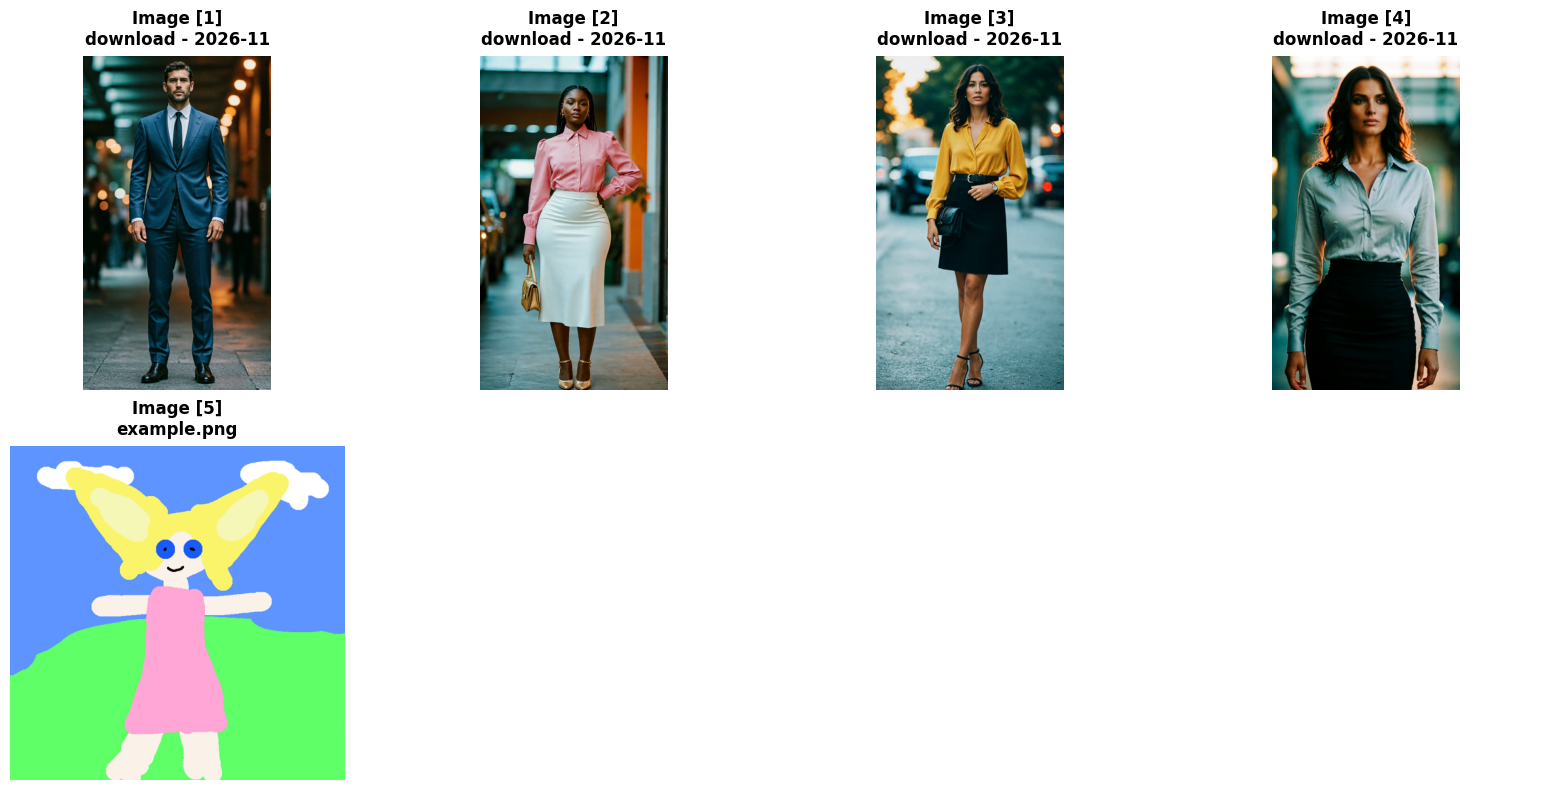

In [50]:
# @title 📥 2. Upload & View Media Bank {"single-column":true}
import os
import math
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt

BANK_DIR = '/content/ComfyUI/input'
os.makedirs(BANK_DIR, exist_ok=True)
os.chdir(BANK_DIR)

print(f"Upload reference images to {BANK_DIR}\n(You can select multiple images at once, or cancel if already uploaded):")
uploaded = files.upload()

os.chdir('/content/ComfyUI')

all_files = os.listdir(BANK_DIR)
available_images = sorted([f for f in all_files if f.lower().endswith(('.png', '.jpg', '.jpeg', '.webp'))])

if available_images:
    print(f"\n--- 🖼️ Image Bank Inventory ({len(available_images)} images) ---")
    cols = 4
    rows = math.ceil(len(available_images) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))

    if rows == 1 and cols == 1:
        axes = [axes]
    else:
        axes = axes.flatten()

    for i, img_name in enumerate(available_images):
        img_path = os.path.join(BANK_DIR, img_name)
        img = Image.open(img_path)
        img.thumbnail((512, 512))

        ax = axes[i]
        ax.imshow(img)
        ax.set_title(f"Image [{i+1}]\n{img_name[:18]}", fontsize=12, fontweight='bold', pad=8)
        ax.axis('off')

    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("\nNo images in the bank yet.")

In [51]:
# @title 🎯 3. Select Media for Generation {"single-column":true}
# @markdown Check Cell 2 for your Image numbers.
# @markdown - **`anchor_image_number`** becomes `image_1` (`<Picture 1>` in the prompt — the primary image to edit, and the aspect ratio anchor when dimensions are set to `0`).
# @markdown - **`additional_image_numbers`** become `image_2`, `image_3`, etc. (`<Picture 2>`, `<Picture 3>`, etc. in the prompt).

import os

BANK_DIR = '/content/ComfyUI/input'
os.makedirs(BANK_DIR, exist_ok=True)

all_files = os.listdir(BANK_DIR)
available_images = sorted([f for f in all_files if f.lower().endswith(('.png', '.jpg', '.jpeg', '.webp'))])

# @markdown ---
anchor_image_number = "1" # @param {type:"string"}
additional_image_numbers = "2, 3, 4" # @param {type:"string"}

image_paths = []

def get_file_path(num_str, file_list):
    if num_str.strip().isdigit():
        idx = int(num_str.strip()) - 1
        if 0 <= idx < len(file_list):
            return os.path.join(BANK_DIR, file_list[idx])
    return None

# 1. Load Anchor Image (Picture 1)
anchor_path = get_file_path(anchor_image_number, available_images)
if anchor_path:
    image_paths.append(anchor_path)

# 2. Load Additional Images (Picture 2, Picture 3, ...)
if additional_image_numbers.strip():
    indices = [int(x.strip()) - 1 for x in additional_image_numbers.split(',') if x.strip().isdigit()]
    for idx in indices:
        if 0 <= idx < len(available_images):
            img_path = os.path.join(BANK_DIR, available_images[idx])
            if img_path not in image_paths:
                image_paths.append(img_path)
        else:
            print(f"⚠️ Warning: Image Number {idx + 1} is out of range.")

print(f"\n✅ Total tracked reference images: {len(image_paths)}")
if image_paths:
    print("\n--- Prompt Tag Mapping ---")
    for idx, path in enumerate(image_paths, start=1):
        role = "Primary Edit / Anchor" if idx == 1 else "Additional Reference"
        print(f"  <Picture {idx}> ({role}): {os.path.basename(path)}")


✅ Total tracked reference images: 4

--- Prompt Tag Mapping ---
  <Picture 1> (Primary Edit / Anchor): download - 2026-11-14T124333.612.png
  <Picture 2> (Additional Reference): download - 2026-11-14T124717.962.png
  <Picture 3> (Additional Reference): download - 2026-11-14T124929.750.png
  <Picture 4> (Additional Reference): download - 2026-11-14T130128.672.png


Active Seed: 81305186114090 | Mode: Image Editing / Reference-to-Image (I2I) | Target Size: 1536x2720
Loading Text Encoder (qwen3vl_32b_minimax_h3_nvfp4_awq.safetensors on default) & VAE (minimax_h3_image_vae_fp16.safetensors)...
Loading <Picture 1>: download - 2026-11-14T124333.612.png
Loading <Picture 2>: download - 2026-11-14T124717.962.png
Loading <Picture 3>: download - 2026-11-14T124929.750.png
Loading <Picture 4>: download - 2026-11-14T130128.672.png
Encoding prompt & reference conditioning...
Loading Diffusion Model (minimax_h3_image_pruned_int8_convrot.safetensors)...
Sampling 1536x2720 image (6 steps, CFG 1.0, euler/simple)...


  0%|          | 0/6 [00:00<?, ?it/s]

Decoding latent with MiniMax-H3-Image VAE...
✅ Saved to: /content/ComfyUI/output/MiniMax_H3_Image_20261114_121621_00001_.png


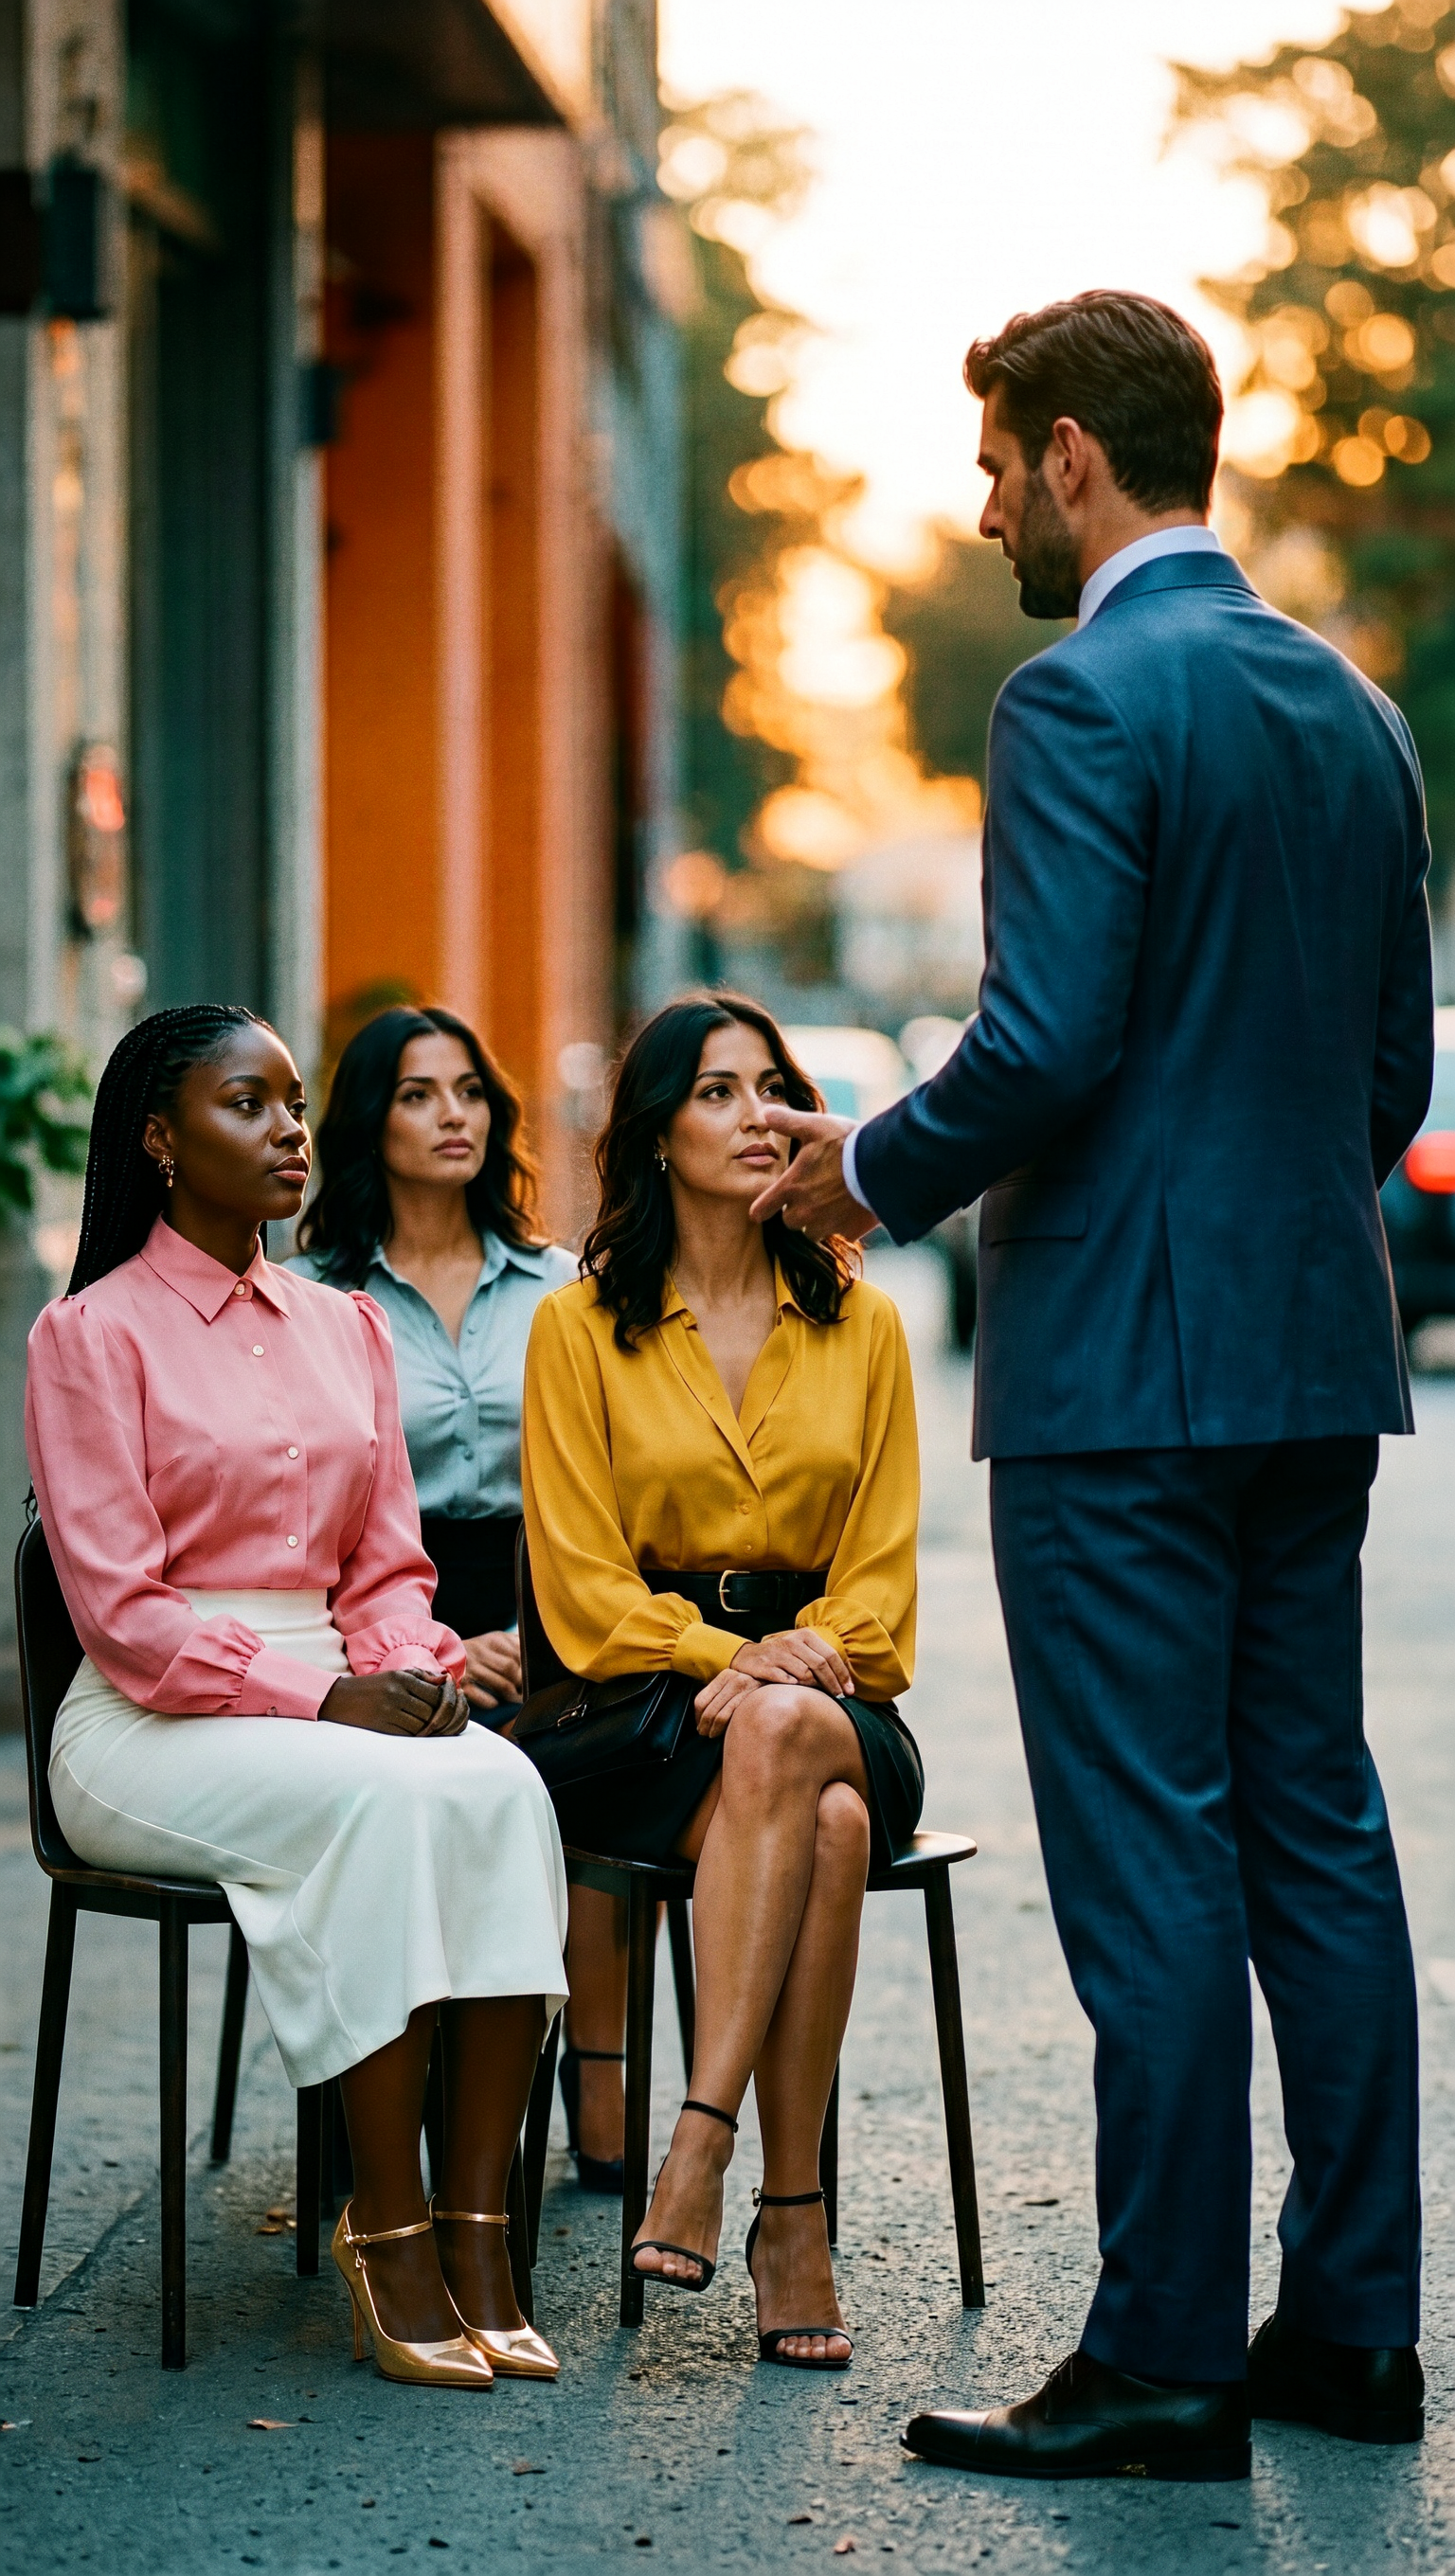

In [54]:
# @title 💥 4. Generate / Edit Image {"single-column":true}
# @markdown > **Resolution & Aspect Ratio Note:** MiniMax-H3-Image operates between **4 MP and 20 MP**, delivering the highest detail at **~16 MP** (`4096x4096` for 1:1, `4736x3552` for 4:3, `5024x3360` for 3:2, `5472x3072` for 16:9, `6272x2688` for 21:9). On lower-VRAM Colab GPUs, use the **4 MP** presets or **Auto (0x0)**. Both sides must be multiples of `32`.

import random
import os
import gc
import time
import torch
from IPython.display import clear_output, display, Image as IPImage

# @markdown ---
# @markdown ### **Generation Mode & Prompting**
mode = "Image Editing / Reference-to-Image (I2I)" # @param ["Text-to-Image (T2I)", "Image Editing / Reference-to-Image (I2I)"]
prompt = "Back view of the man in suit in <picture 1>, standing and speaking to the front views of the other people. The people in <picture 2>, <picture 3>, and <picture 4> are all seated on a chair, all looking at the man in <picture 1>." # @param {type:"string"}
extra_details = "Cinematic film still, sharp focus. Shot on 35mm lens, shallow depth of field, beautiful bokeh. Volumetric ambient lighting. Kodak Vision3, subtle film grain, teal and orange color grading."  # @param {"type":"string"}
prompt = f"{prompt} {extra_details}".strip()

# @markdown ---
# @markdown ### **Aspect Ratio & Canvas Size**
resolution_preset = "9:16 Vertical - 4 MP (1536x2720)" # @param ["Auto (0x0 - Follows <Picture 1> or 2048x2048)", "1:1 Square - 16 MP Recommended (4096x4096)", "4:3 Standard - 16 MP Recommended (4736x3552)", "3:4 Portrait - 16 MP Recommended (3552x4736)", "3:2 Photo - 16 MP Recommended (5024x3360)", "2:3 Portrait Photo - 16 MP Recommended (3360x5024)", "16:9 Widescreen - 16 MP Recommended (5472x3072)", "9:16 Vertical - 16 MP Recommended (3072x5472)", "21:9 Ultrawide - 16 MP Recommended (6272x2688)", "1:1 Square - 4 MP (2048x2048 - Fast / Low VRAM)", "4:3 Standard - 4 MP (2368x1760)", "3:4 Portrait - 4 MP (1760x2368)", "3:2 Photo - 4 MP (2496x1664)", "2:3 Portrait Photo - 4 MP (1664x2496)", "16:9 Widescreen - 4 MP (2720x1536)", "9:16 Vertical - 4 MP (1536x2720)", "21:9 Ultrawide - 4 MP (3136x1344)", "Custom Resolution (Use custom_width & custom_height)"]
custom_width = 1024 # @param {type:"integer"}
custom_height = 1824 # @param {type:"integer"}

# @markdown ---
# @markdown ### **Model Precision, Offloading & VAE Anchoring**
weight_dtype = "default" # @param ["default", "fp8_e4m3fn", "fp8_e4m3fn_fast", "fp8_e5m2"]
clip_device = "default" # @param ["default", "cpu"]
anchor_refs_with_vae = True

# @markdown ---
# @markdown ### **Sampling & Seed (Distilled Default: 6 Steps, CFG 1.0, euler, simple)**
seed = 0 # @param {type:"integer"}
steps = 6 # @param {type:"integer", min:1, max:50}
cfg = 1.0 # @param {type:"number", min:1.0, max:20.0}
sampler_name = "euler" # @param ["euler", "euler_ancestral", "uni_pc", "uni_pc_bh2", "ddim", "heun", "dpm_2", "dpmpp_2m", "dpmpp_2m_sde", "dpmpp_sde", "res_multistep"]
scheduler = "simple" # @param ["simple", "normal", "karras", "exponential", "sgm_uniform", "ddim_uniform", "beta"]

# @markdown ---
# @markdown ### **Custom LoRAs Strengths (Set non-zero to activate)**
lora_1_strength = 0.0 # @param {type:"number", min:-2.0, max:2.0}
lora_2_strength = 0.0 # @param {type:"number", min:-2.0, max:2.0}
lora_3_strength = 0.0 # @param {type:"number", min:-2.0, max:2.0}
lora_4_strength = 0.0 # @param {type:"number", min:-2.0, max:2.0}
lora_5_strength = 0.0 # @param {type:"number", min:-2.0, max:2.0}

if seed == 0:
    seed = random.randint(1, 100000000000000)

# Parse Resolution Preset
preset_map = {
    "Auto (0x0 - Follows <Picture 1> or 2048x2048)": (0, 0),
    "1:1 Square - 16 MP Recommended (4096x4096)": (4096, 4096),
    "4:3 Standard - 16 MP Recommended (4736x3552)": (4736, 3552),
    "3:4 Portrait - 16 MP Recommended (3552x4736)": (3552, 4736),
    "3:2 Photo - 16 MP Recommended (5024x3360)": (5024, 3360),
    "2:3 Portrait Photo - 16 MP Recommended (3360x5024)": (3360, 5024),
    "16:9 Widescreen - 16 MP Recommended (5472x3072)": (5472, 3072),
    "9:16 Vertical - 16 MP Recommended (3072x5472)": (3072, 5472),
    "21:9 Ultrawide - 16 MP Recommended (6272x2688)": (6272, 2688),
    "1:1 Square - 4 MP (2048x2048 - Fast / Low VRAM)": (2048, 2048),
    "4:3 Standard - 4 MP (2368x1760)": (2368, 1760),
    "3:4 Portrait - 4 MP (1760x2368)": (1760, 2368),
    "3:2 Photo - 4 MP (2496x1664)": (2496, 1664),
    "2:3 Portrait Photo - 4 MP (1664x2496)": (1664, 2496),
    "16:9 Widescreen - 4 MP (2720x1536)": (2720, 1536),
    "9:16 Vertical - 4 MP (1536x2720)": (1536, 2720),
    "21:9 Ultrawide - 4 MP (3136x1344)": (3136, 1344),
}

if resolution_preset in preset_map:
    width, height = preset_map[resolution_preset]
else:
    width = 0 if custom_width == 0 else max(32, round(custom_width / 32) * 32)
    height = 0 if custom_height == 0 else max(32, round(custom_height / 32) * 32)

print(f"Active Seed: {seed} | Mode: {mode} | Target Size: {width if width else 'Auto'}x{height if height else 'Auto'}")

def generate_minimax_h3_image():
    model = clip = vae = None
    cond_out = neg_cond = latent_out = sampled_latent = decoded_images = None

    try:
        with torch.inference_mode():
            unet_loader = UNETLoader()
            clip_loader = CLIPLoader()
            vae_loader = VAELoader()
            load_img_node = LoadImage()
            lora_loader = LoraLoaderModelOnly()

            unet_file = os.path.basename(unet_model_file)
            text_enc_file = os.path.basename(text_encoder_file)
            vae_file = os.path.basename(image_vae_file)

            # 1. Load Text Encoder & VAE first for conditioning
            print(f"Loading Text Encoder ({text_enc_file} on {clip_device}) & VAE ({vae_file})...")
            if text_enc_file.lower().endswith(".gguf"):
                from custom_nodes.ComfyUI_GGUF.nodes import CLIPLoaderGGUF
                clip = CLIPLoaderGGUF().load_clip(text_enc_file, type="minimax")[0]
            else:
                clip = clip_loader.load_clip(text_enc_file, type="minimax", device=clip_device)[0]

            vae = vae_loader.load_vae(vae_file)[0]

            # 2. Load Reference Images if in Editing / I2I mode
            safe_image_paths = globals().get('image_paths', [])
            ref_images_dict = {}
            needs_visual_ref = "I2I" in mode

            if safe_image_paths and needs_visual_ref:
                for idx, path in enumerate(safe_image_paths, start=1):
                    if os.path.exists(path):
                        print(f"Loading <Picture {idx}>: {os.path.basename(path)}")
                        tensor = load_img_node.load_image(os.path.basename(path))[0]
                        ref_images_dict[f"image_{idx}"] = tensor
            elif needs_visual_ref and not safe_image_paths:
                print("⚠️ Warning: Image Editing mode selected, but no images were selected in Cell 3. Running Text-to-Image.")

            # 3. Execute MiniMaxH3ImageConditioning
            print("Encoding prompt & reference conditioning...")
            cond_result = MiniMaxH3ImageConditioning.execute(
                clip=clip,
                prompt=prompt,
                width=width,
                height=height,
                vae=vae if (ref_images_dict and anchor_refs_with_vae) else None,
                images=ref_images_dict if ref_images_dict else None
            )

            if type(cond_result).__name__ == 'NodeOutput' or hasattr(cond_result, "__iter__"):
                cond_out, latent_out = list(cond_result)[:2]
            else:
                cond_out, latent_out = cond_result[0], cond_result[1]

            neg_cond = ConditioningZeroOut().zero_out(cond_out)[0]

            # Free Text Encoder from VRAM before loading the 33B DiT
            clip = None
            gc.collect()
            torch.cuda.empty_cache()

            # 4. Load Diffusion Model (Safetensors or GGUF)
            print(f"Loading Diffusion Model ({unet_file})...")
            if unet_file.lower().endswith(".gguf"):
                from custom_nodes.ComfyUI_GGUF.nodes import UnetLoaderGGUF
                model = UnetLoaderGGUF().load_unet(unet_file)[0]
            else:
                model = unet_loader.load_unet(unet_file, weight_dtype=weight_dtype)[0]

            # 5. Chain Active Custom LoRAs (1 to 5)
            lora_strengths = [lora_1_strength, lora_2_strength, lora_3_strength, lora_4_strength, lora_5_strength]
            for idx, l_fname in enumerate(globals().get('lora_files', [])):
                if idx < 5 and l_fname:
                    st = lora_strengths[idx]
                    if st != 0.0 and os.path.exists(f"/content/ComfyUI/models/loras/{l_fname}"):
                        print(f"Applying LoRA {idx+1}: {l_fname} (Strength: {st})")
                        model = lora_loader.load_lora_model_only(model, l_fname, st)[0]

            # 6. Sample Latents via KSampler
            latent_h = latent_out["samples"].shape[-2] * 16
            latent_w = latent_out["samples"].shape[-1] * 16
            print(f"Sampling {latent_w}x{latent_h} image ({steps} steps, CFG {cfg}, {sampler_name}/{scheduler})...")

            sampled_latent = KSampler().sample(
                model=model,
                seed=seed,
                steps=steps,
                cfg=cfg,
                sampler_name=sampler_name,
                scheduler=scheduler,
                positive=cond_out,
                negative=neg_cond,
                latent_image=latent_out,
                denoise=1.0
            )[0]

            # Free Diffusion Model before High-Res VAE Decoding
            model = None
            gc.collect()
            torch.cuda.empty_cache()

            # 7. Decode Latents & Save Output
            print("Decoding latent with MiniMax-H3-Image VAE...")
            decoded_images = VAEDecode().decode(vae, sampled_latent)[0]

            vae = None
            gc.collect()
            torch.cuda.empty_cache()

            timestamp = time.strftime("%Y%m%d_%H%M%S")
            output_prefix = f"MiniMax_H3_Image_{timestamp}"

            save_node = SaveImage()
            save_node.save_images(images=decoded_images, filename_prefix=output_prefix)

            out_dir = "/content/ComfyUI/output"
            matching_files = sorted([
                os.path.join(out_dir, f)
                for f in os.listdir(out_dir)
                if f.startswith(output_prefix) and f.endswith((".png", ".jpg", ".webp"))
            ])

            if matching_files:
                print(f"✅ Saved to: {matching_files[-1]}")
                display(IPImage(filename=matching_files[-1]))
            else:
                print("❌ Image generation finished, but output file could not be located.")

    finally:
        model = clip = vae = cond_out = neg_cond = latent_out = sampled_latent = decoded_images = None
        gc.collect()
        torch.cuda.empty_cache()

generate_minimax_h3_image()